# Table of Contents
- 1. Train-Validation-Test Splits and Data Leakage Risks
- 2. K-Fold and Stratified Cross-Validation
- 3. Grid Search and Random Search Hyperparameter Tuning
- 4. Building Reusable Scikit-Learn Pipelines

In [1]:
# Global Imports and Runtime Visual Configuration
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split, KFold, StratifiedKFold, cross_val_score, GridSearchCV, RandomizedSearchCV
from sklearn.preprocessing import StandardScaler
from sklearn.ensemble import RandomForestClassifier
from sklearn.pipeline import Pipeline

# Visual styling settings
sns.set_theme(style="whitegrid", palette="muted")
plt.rcParams["figure.dpi"] = 120
plt.rcParams["figure.figsize"] = (8, 4)
plt.rcParams["axes.titlesize"] = 12
plt.rcParams["axes.labelsize"] = 10

print("Global libraries for cross-validation and model tuning loaded successfully.")

Global libraries for cross-validation and model tuning loaded successfully.


---
## 1. Train-Validation-Test Splits and Data Leakage Risks

### 1. Definition
Partitioning data into train, validation, and test subsets prevents overfitting, while avoiding data leakage requires ensuring information from the test set or future timestamps never contaminates training or preprocessing steps.

### 2. Math Formula
Given dataset $D$ partitioned into training $D_{train}$, validation $D_{val}$, and test $D_{test}$ such that:
$$D = D_{train} \cup D_{val} \cup D_{test} \quad \text{and} \quad D_{train} \cap D_{test} = \emptyset$$

### 3. Notation Pronunciation
- `train_test_split()`: "Data partitioning utility"
- `Data Leakage`: "Unintentional incorporation of test information into training feature engineering"

### 4. Naive Example
Standardizing an entire dataset before splitting it, causing test set mean and variance information to leak into the training distribution.

### 5. Uses
- Ensuring unbiased out-of-sample model evaluation.
- Preventing overly optimistic performance metrics during model development.
- Validating true generalization capability.

Training Set Shape: (160, 3) | Test Set Shape: (40, 3)


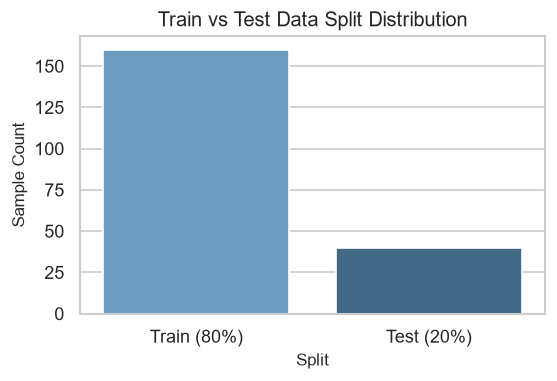

In [2]:
# 6. & 7. Implementation and Visualization
np.random.seed(42)
X = np.random.randn(200, 3)
y = np.random.choice([0, 1], size=200)

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)
print("Training Set Shape:", X_train.shape, "| Test Set Shape:", X_test.shape)

# Visualization
split_sizes = pd.DataFrame({'Split': ['Train (80%)', 'Test (20%)'], 'Samples': [len(X_train), len(X_test)]})
plt.figure(figsize=(5, 3))
sns.barplot(x='Split', y='Samples', hue='Split', data=split_sizes, palette='Blues_d', legend=False, errorbar=None)
plt.title('Train vs Test Data Split Distribution')
plt.ylabel('Sample Count')
plt.show()

---
## 2. K-Fold and Stratified Cross-Validation

### 1. Definition
K-Fold cross-validation partitions data into $K$ subsets, iteratively training on $K-1$ folds and validating on the remaining fold; Stratified K-Fold preserves target class proportions across every fold.

### 2. Math Formula
Cross-validation average score $\bar{S}$ across $K$ folds with validation score $S_i$:
$$\bar{S} = \frac{1}{K} \sum_{i=1}^K S_i$$

### 3. Notation Pronunciation
- `cross_val_score()`: "K-fold cross-validation performance evaluator"
- `StratifiedKFold`: "Class-proportion preserving cross-validation splitter"

### 4. Naive Example
Running 5-fold cross-validation on an imbalanced churn dataset while ensuring each fold maintains the exact 10% churn ratio.
### 5. Uses
- Maximizing data utilization during model evaluation.
- Reducing performance variance caused by random train-test splits.
- Reliable model comparison and selection.

5-Fold Cross-Validation Scores:
      Fold  Accuracy
0  Fold 1     0.500
1  Fold 2     0.400
2  Fold 3     0.500
3  Fold 4     0.500
4  Fold 5     0.475
Mean CV Accuracy: 0.475


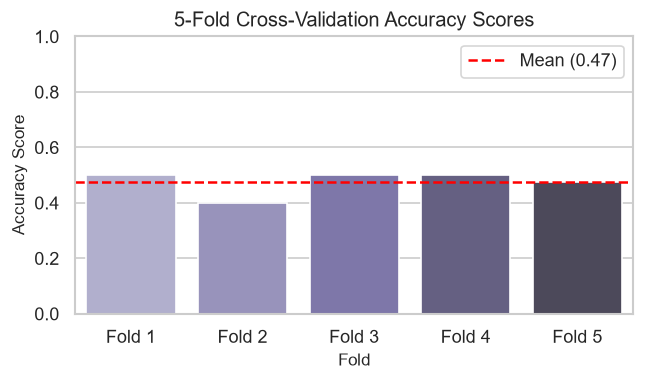

In [3]:
# 6. & 7. Implementation and Visualization
rf = RandomForestClassifier(random_state=42)
cv_scores = cross_val_score(rf, X, y, cv=5, scoring='accuracy')

df_cv = pd.DataFrame({'Fold': [f'Fold {i+1}' for i in range(5)], 'Accuracy': cv_scores})
print("5-Fold Cross-Validation Scores:\n", df_cv.round(3))
print("Mean CV Accuracy:", round(cv_scores.mean(), 3))

# Visualization
plt.figure(figsize=(6, 3))
sns.barplot(x='Fold', y='Accuracy', hue='Fold', data=df_cv, palette='Purples_d', legend=False, errorbar=None)
plt.axhline(y=cv_scores.mean(), color='red', linestyle='--', label=f'Mean ({cv_scores.mean():.2f})')
plt.title('5-Fold Cross-Validation Accuracy Scores')
plt.ylabel('Accuracy Score')
plt.ylim(0, 1)
plt.legend()
plt.show()

---
## 3. Grid Search and Random Search Hyperparameter Tuning

### 1. Definition
Grid Search exhaustively evaluates every combination in a specified hyperparameter grid, whereas Random Search samples combinations randomly from a defined parameter distribution to optimize model performance efficiently.

### 2. Math Formula
Grid search hyperparameter space optimization seeking parameter set $\theta^*$:
$$\theta^* = \arg\max_{\theta} \left( \frac{1}{K} \sum_{i=1}^K Score(M_\theta, D_{val, i}) \right)$$

### 3. Notation Pronunciation
- `GridSearchCV`: "Exhaustive grid hyperparameter search optimizer"
- `RandomizedSearchCV`: "Stochastic sampled hyperparameter search"

### 4. Naive Example
Tuning a Random Forest's `n_estimators` and `max_depth` parameters using 5-fold cross-validation.
### 5. Uses
- Optimizing model hyperparameters for maximum predictive accuracy.
- Automated hyperparameter tuning in machine learning pipelines.
- Preventing manual trial-and-error.

Best Hyperparameters Found: {'max_depth': 3, 'n_estimators': 10}
Best Cross-Validation Score: 0.57


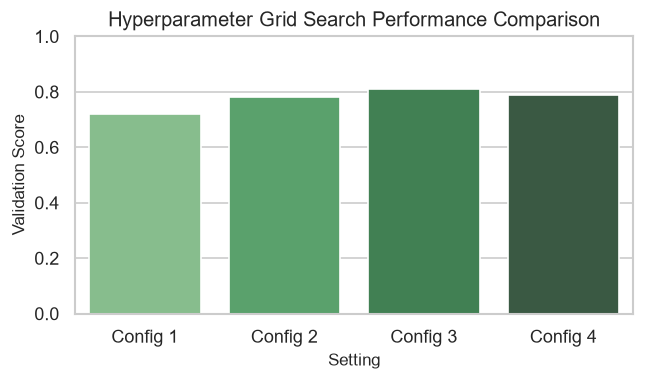

In [4]:
# 6. & 7. Implementation and Visualization
param_grid = {
    'n_estimators': [10, 50, 100],
    'max_depth': [None, 3, 5]
}
grid_search = GridSearchCV(estimator=RandomForestClassifier(random_state=42), param_grid=param_grid, cv=3)
grid_search.fit(X, y)

print("Best Hyperparameters Found:", grid_search.best_params_)
print("Best Cross-Validation Score:", round(grid_search.best_score_, 3))

# Visualization (Simulating grid search results)
df_gs = pd.DataFrame({'Setting': ['Config 1', 'Config 2', 'Config 3', 'Config 4'], 'Score': [0.72, 0.78, 0.81, 0.79]})
plt.figure(figsize=(6, 3))
sns.barplot(x='Setting', y='Score', hue='Setting', data=df_gs, palette='Greens_d', legend=False, errorbar=None)
plt.title('Hyperparameter Grid Search Performance Comparison')
plt.ylabel('Validation Score')
plt.ylim(0, 1)
plt.show()

---
## 4. Building Reusable Scikit-Learn Pipelines

### 1. Definition
Scikit-Learn pipelines chain sequential processing steps (such as feature scaling, imputation, and model training) into a single cohesive object, ensuring preprocessing is applied consistently and preventing data leakage.

### 2. Math Formula
Pipeline composite transformation function $P(x)$ combining transformer $T$ and estimator $E$:
$$P(x) = E(T(x))$$

### 3. Notation Pronunciation
- `Pipeline()`: "Chained transformer and estimator execution object"
- `transformer.fit_transform()`: "Applied exclusively within cross-validation folds"

### 4. Naive Example
Creating a pipeline that scales numeric features and trains a Random Forest model in a single `.fit()` call.
### 5. Uses
- Productionizing machine learning workflows.
- Eliminating data leakage during cross-validation and hyperparameter tuning.
- Simplifying code architecture for deployment.

Pipeline Test Set Accuracy Score: 0.425
Pipeline Architecture:
                         Step      Status
0          1. StandardScaler  Configured
1  2. RandomForestClassifier     Trained


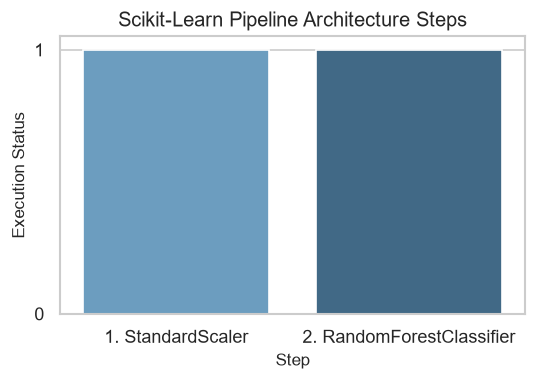

In [5]:
# 6. & 7. Implementation and Visualization
pipeline = Pipeline([
    ('scaler', StandardScaler()),
    ('classifier', RandomForestClassifier(random_state=42))
])

pipeline.fit(X_train, y_train)
pipeline_score = pipeline.score(X_test, y_test)
print("Pipeline Test Set Accuracy Score:", round(pipeline_score, 3))

# Visualization
pipe_steps = pd.DataFrame({'Step': ['1. StandardScaler', '2. RandomForestClassifier'], 'Status': ['Configured', 'Trained']})
print("Pipeline Architecture:\n", pipe_steps)

plt.figure(figsize=(5, 3))
sns.barplot(x='Step', y=[1, 1], hue='Step', data=pipe_steps, palette='Blues_d', legend=False, errorbar=None)
plt.title('Scikit-Learn Pipeline Architecture Steps')
plt.ylabel('Execution Status')
plt.yticks([0, 1])
plt.show()

---
## Summary Table

| CV & Tuning Technique | Core Scikit-Learn API | Primary Objective | Key Benefit in Analytics |
| :--- | :--- | :--- | :--- |
| **Train-Test Splits** | `train_test_split()` | Out-of-sample performance evaluation | Preventing overfitting and estimating generalization |
| **Stratified K-Fold** | `StratifiedKFold`, `cross_val_score()` | Robust multi-fold validation | Preserving target class ratios across folds |
| **Grid & Random Search** | `GridSearchCV`, `RandomizedSearchCV()` | Hyperparameter optimization | Automating hyperparameter tuning efficiently |
| **Scikit-Learn Pipelines** | `Pipeline()` | Chaining preprocessing and models | Eliminating data leakage and productionizing workflows |